**Disciplina:** Tópicos Especiais de Energia – Transferência de Calor utilizando PINNs (UFABC, 3º quadrimestre de 2026)
**Professores:** Prof. Dr. Daniel Jonas Dezan e Prof. MSc. Paulo de Souza Silva
**Aluno:** _preencher com o nome completo_
**Lista 2 – Condução e Solução de Blasius em Python**

Obs.: notebook desenvolvido com auxílio de ferramentas de IA, como permitido no enunciado; o código e os resultados foram executados e conferidos.

# **Exercício 1 – Fundamentos de Python e difusão sem geração de energia**

**Notebook de apoio:** `Aula03_Parte1_1D_Estacionario.ipynb`

## **Enunciado (resumo)**

Parede plana de comprimento $L = 2$ m, condução 1D em regime permanente, **sem geração** de energia e com $k$ constante. As superfícies estão em $T_{s1}$ ($x=0$) e $T_{s2}$ ($x=L$). A solução analítica é

$$
T(x) = T_{s1} + \frac{T_{s2}-T_{s1}}{L}\,x, \qquad 0 \le x \le L.
$$

Em todos os itens usamos **10 pontos igualmente espaçados** em $0 \le x \le L$.

## **Formulação**

Sem geração e com $k$ constante, a equação do calor se reduz a

$$
\frac{d^2T}{dx^2} = 0 \;\Rightarrow\; T(x) = c_1 x + c_2 .
$$

Aplicando $T(0)=T_{s1}$ e $T(L)=T_{s2}$: $c_2 = T_{s1}$ e $c_1 = (T_{s2}-T_{s1})/L$. O perfil é sempre uma **reta**, cuja inclinação depende apenas da diferença de temperatura entre as faces.

In [1]:
# Bibliotecas utilizadas
import os
import numpy as np                  # funções matemáticas e vetores
import matplotlib.pyplot as plt     # gráficos

os.makedirs("figuras", exist_ok=True)   # pasta onde as figuras são salvas
plt.rcParams["figure.dpi"] = 110

## Geometria e malha
L = 2.0                        # comprimento da parede [m]
N_pontos = 10                  # número de pontos igualmente espaçados
x = np.linspace(0, L, N_pontos)   # posições [m]

def T_sem_geracao(x, Ts1, Ts2, L):
    # Solução analítica: perfil linear entre Ts1 (x=0) e Ts2 (x=L)
    return Ts1 + (Ts2 - Ts1) / L * x

## **Item a)** $T_{s1} = 300$ K e $T_{s2} = 200$ K

In [2]:
Ts1_a, Ts2_a = 300.0, 200.0        # [K]
T_a = T_sem_geracao(x, Ts1_a, Ts2_a, L)

np.set_printoptions(precision=4, suppress=True)
print("Item a) Ts1 = 300 K, Ts2 = 200 K")
print(f"x    [m] = {x}")
print(f"T(x) [K] = {T_a}")
print(f"Gradiente dT/dx = {(Ts2_a - Ts1_a) / L:.1f} K/m")

Item a) Ts1 = 300 K, Ts2 = 200 K
x    [m] = [0.     0.2222 0.4444 0.6667 0.8889 1.1111 1.3333 1.5556 1.7778 2.    ]
T(x) [K] = [300.     288.8889 277.7778 266.6667 255.5556 244.4444 233.3333 222.2222
 211.1111 200.    ]
Gradiente dT/dx = -50.0 K/m


## **Item b)** $T_{s1} = 500$ K e $T_{s2} = 200$ K

In [3]:
Ts1_b, Ts2_b = 500.0, 200.0        # [K]
T_b = T_sem_geracao(x, Ts1_b, Ts2_b, L)

print("Item b) Ts1 = 500 K, Ts2 = 200 K")
print(f"x    [m] = {x}")
print(f"T(x) [K] = {T_b}")
print(f"Gradiente dT/dx = {(Ts2_b - Ts1_b) / L:.1f} K/m")

Item b) Ts1 = 500 K, Ts2 = 200 K
x    [m] = [0.     0.2222 0.4444 0.6667 0.8889 1.1111 1.3333 1.5556 1.7778 2.    ]
T(x) [K] = [500.     466.6667 433.3333 400.     366.6667 333.3333 300.     266.6667
 233.3333 200.    ]
Gradiente dT/dx = -150.0 K/m


## **Item c)** Gráfico único com as duas soluções

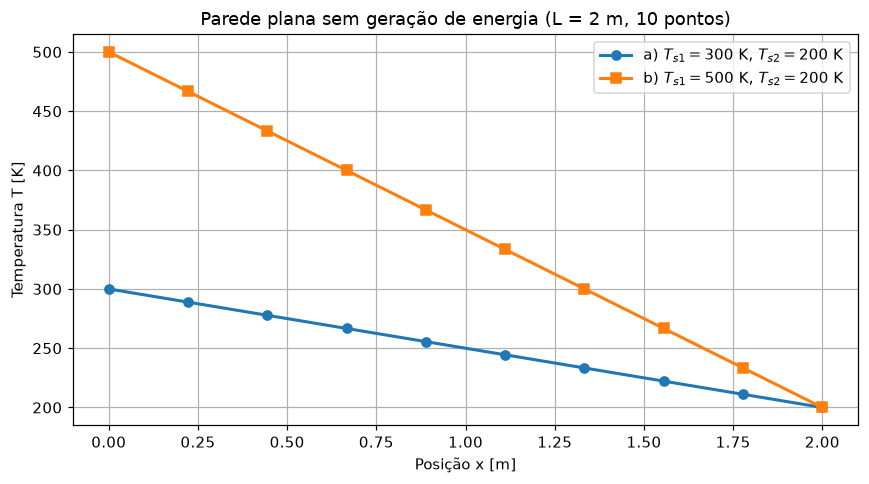

In [4]:
plt.figure(figsize=(8, 4.5))
plt.plot(x, T_a, "o-", linewidth=2, label=r"a) $T_{s1}=300$ K, $T_{s2}=200$ K")
plt.plot(x, T_b, "s-", linewidth=2, label=r"b) $T_{s1}=500$ K, $T_{s2}=200$ K")
plt.xlabel("Posição x [m]")
plt.ylabel("Temperatura T [K]")
plt.title("Parede plana sem geração de energia (L = 2 m, 10 pontos)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("figuras/ex1_perfis_temperatura.png", dpi=300, bbox_inches="tight")
plt.show()

## **Comentário**

- Nos dois casos o perfil é **linear**, como esperado para condução 1D permanente sem geração e com $k$ constante: os 10 pontos ficam sobre uma reta.
- A face direita é a mesma ($200$ K), mas no item b) a diferença entre as faces é três vezes maior ($300$ K contra $100$ K). Por isso, o gradiente passa de $-50$ K/m para $-150$ K/m.
- Pela lei de Fourier, $q'' = -k\,dT/dx$. Para o mesmo material, o fluxo de calor no item b) seria **três vezes maior** que no item a).